In [1]:

!pip install pandas numpy matplotlib seaborn scikit-learn


In [9]:

from google.colab import files

uploaded = files.upload()


Saving train.csv to train.csv


In [10]:

import pandas as pd
import numpy as np

df = pd.read_csv("train.csv")

print("Dataset Loaded Successfully!")
print(df.head())
print("Dataset Shape:", df.shape)


Dataset Loaded Successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450

In [11]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [12]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
# Fill missing Age with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop Cabin column
df = df.drop('Cabin', axis=1)

# Check missing values again
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [14]:
print("Dataset Shape:", df.shape)

print("Total Missing Values:",
      df.isnull().sum().sum())

print("Total Duplicate Rows:",
      df.duplicated().sum())

Dataset Shape: (891, 11)
Total Missing Values: 0
Total Duplicate Rows: 0


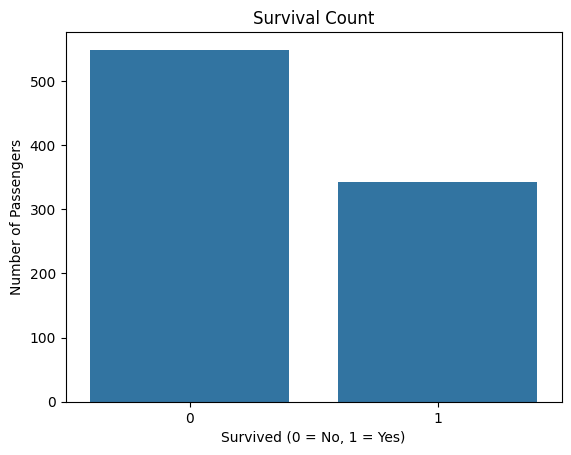

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='Survived')

plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


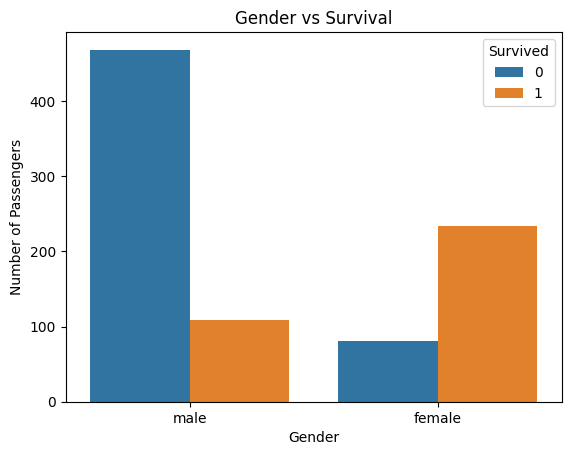

In [16]:

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Gender vs Survival")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()


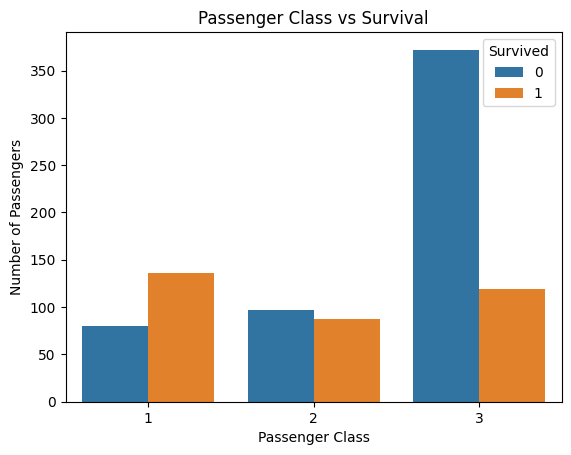

In [17]:

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title("Passenger Class vs Survival")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()


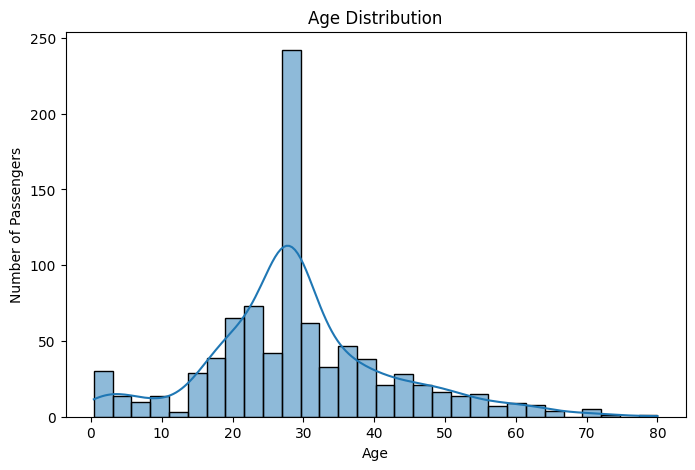

In [18]:

plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()


In [19]:

from sklearn.model_selection import train_test_split

# Separate input and output
X = df.drop(['Survived', 'PassengerId', 'Name', 'Ticket'], axis=1)

y = df['Survived']

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)


Training Data: (712, 7)
Testing Data: (179, 7)
Training Labels: (712,)
Testing Labels: (179,)


In [20]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Numerical and categorical columns
numeric_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Sex', 'Embarked']

# Preprocessing
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# Create ML model
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

print("Model created successfully!")


Model created successfully!


In [21]:

# Train the model
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")


Model Training Completed Successfully!


In [22]:

# Predict on test data
y_pred = model.predict(X_test)

print("First 10 Predictions:")
print(y_pred[:10])

print("\nActual Values:")
print(y_test.values[:10])


First 10 Predictions:
[0 0 0 0 1 0 1 0 0 0]

Actual Values:
[0 0 1 0 1 1 1 0 0 0]


In [23]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 80.44692737430168 %


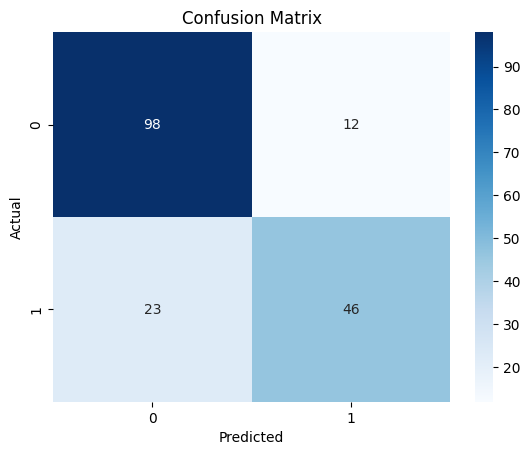

In [24]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


In [25]:

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

# Train model
dt_model.fit(X_train, y_train)

# Prediction
dt_pred = dt_model.predict(X_test)

print("Decision Tree Training Completed!")


Decision Tree Training Completed!


In [26]:

from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:",
      dt_accuracy * 100, "%")


Decision Tree Accuracy: 76.53631284916202 %


In [27]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    ))
])

# Train model
rf_model.fit(X_train, y_train)

# Prediction
rf_pred = rf_model.predict(X_test)

print("Random Forest Training Completed!")


Random Forest Training Completed!


In [28]:

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:",
      rf_accuracy * 100, "%")


Random Forest Accuracy: 81.56424581005587 %


In [29]:

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100
    ]
})

print(results.sort_values(
    by='Accuracy',
    ascending=False
))


                 Model   Accuracy
2        Random Forest  81.564246
0  Logistic Regression  80.446927
1        Decision Tree  76.536313


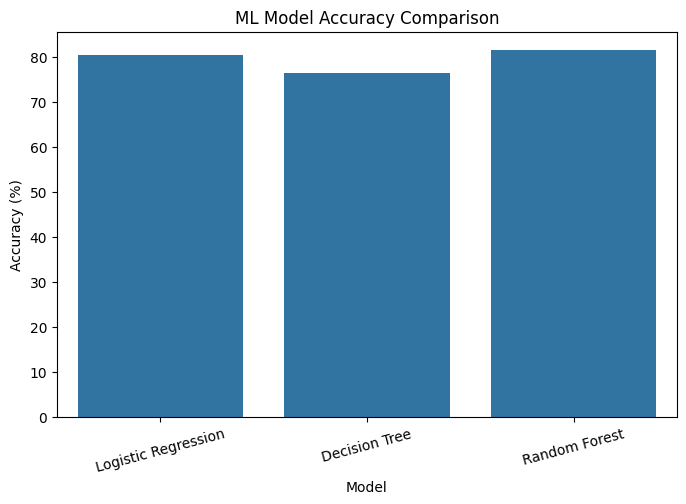

In [30]:

plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("ML Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.show()


In [31]:

from sklearn.metrics import classification_report

print("Random Forest Classification Report:")

print(classification_report(y_test, rf_pred))


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.88      0.61      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.83      0.82      0.81       179



In [32]:

import joblib

# Compare all models
model_scores = {
    "Logistic Regression": accuracy,
    "Decision Tree": dt_accuracy,
    "Random Forest": rf_accuracy
}

# Select best model
best_model_name = max(model_scores, key=model_scores.get)

if best_model_name == "Logistic Regression":
    best_model = model
elif best_model_name == "Decision Tree":
    best_model = dt_model
else:
    best_model = rf_model

print("Best Model:", best_model_name)
print("Best Accuracy:", model_scores[best_model_name] * 100)

# Save model
joblib.dump(best_model, "titanic_model.pkl")

print("Model Saved Successfully!")


Best Model: Random Forest
Best Accuracy: 81.56424581005587
Model Saved Successfully!
